In [1]:
import scanpy as sc
import numpy as np
import scprep
from anndata import AnnData
import phate
from phate.cluster import kmeans
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [2]:
import sys
sys.path.append('..')
from dhg import Hypergraph
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.data import HGDataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Dataset
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping
from torch.utils.data import random_split
from pytorch_lightning.loggers import TensorBoardLogger
from hypgs import DATA_DIR
import anndata
import os
import torch
import numpy as np
import phate
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
import scanpy as sc
from sklearn.neighbors import kneighbors_graph
import random 
from torch_geometric.utils.convert import from_networkx
from importlib import reload
from hypgs.models.hsn_pyg import HyperScatteringModule
from torch_geometric.utils.convert import from_networkx
from einops import rearrange
from scipy.spatial import ConvexHull
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.hypergraph_utils import get_cliques_planar
from scipy.spatial import Voronoi, voronoi_plot_2d
from hypgs.utils.graph_build import calcualte_voronoi_from_coords, build_graph_from_cell_coords, build_graph_from_voronoi_polygons, build_voronoi_polygon_to_cell_mapping, plot_voronoi_polygons, plot_graph, assign_attributes
from hypgs.utils.plot import get_wv_plots
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
adata_subset = sc.read_h5ad("merfish_H20.33.001.CX28.MTG.02.007.1.02.02.h5ad", backed='r')

In [4]:
coordinates = adata_subset.obsm['X_selected_cell_spatial_tiled']
coordinates = coordinates - coordinates.min(axis=0)
xmax, ymax = coordinates.max(axis=0)
voronoi_polygons = calcualte_voronoi_from_coords(coordinates[:, 0], coordinates[:, 1])
cell_data = pd.DataFrame(np.c_[adata_subset.obs.index, coordinates], columns=['CELL_ID', 'X', 'Y'])
G, node_to_cell_mapping = build_graph_from_cell_coords(cell_data, voronoi_polygons)
G = assign_attributes(G, cell_data, node_to_cell_mapping)

In [5]:
num_hops = 1
X_data = adata_subset[:,:].X.toarray()
data = from_networkx(G)
data.x = torch.tensor(X_data)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, num_hops)
dataset = HGDataset(original_dataset, to_hg_func)
eidf = get_hyperedge_pos_df(dataset[0], coordinates)
enlarged_hulls = compute_enlarged_hulls(eidf)
model = HyperScatteringModule(in_channels=1, # doesn't matter here.
            trainable_laziness = False,
            trainable_scales = False, 
            activation = None, # just get one layer of wavelet transform 
            fixed_weights=True, 
            normalize='right', 
            reshape=False,
    ).to(device)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/utils/convert.py:260: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:261.)
  data[key] = torch.tensor(value)
Converting to hypergraph data: 100%|██████████| 1/1 [00:16<00:00, 16.30s/it]


In [6]:
init_node_sig = torch.from_numpy(X_data).to(device)
init_he_sig = torch.zeros(dataset[0].edge_attr.shape[0], X_data.shape[1], device=device)
heidx = dataset[0].edge_index.to(device)
s_nodes, s_edges = model(init_node_sig, heidx, hyperedge_attr = init_he_sig)

In [7]:
wvs = [s_edges[0,i,...].detach().cpu().numpy() for i in range(6)]
wvs_phate = []
phate_ops = []
for i in range(6):
    phate_op = phate.PHATE(verbose=0)
    wv0 = wvs[i]
    wv0_phate = phate_op.fit_transform(wv0)
    wvs_phate.append(wv0_phate)
    phate_ops.append(phate_op)

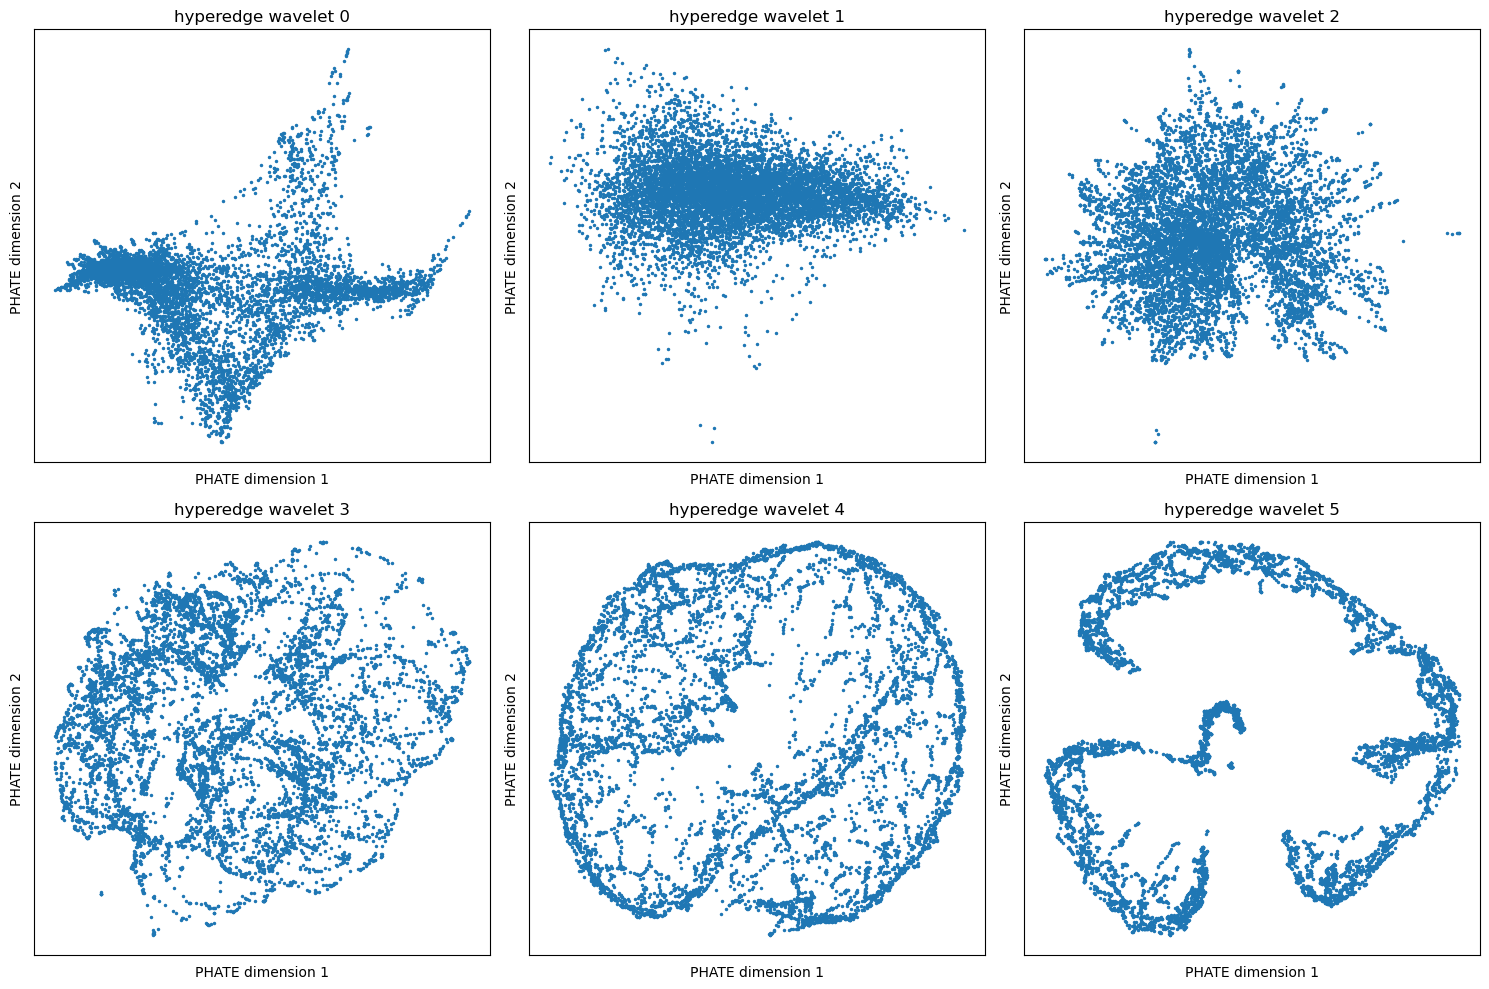

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    wv_phate = wvs_phate[i]
    scprep.plot.scatter2d(wv_phate, ax=ax, legend_loc='lower right')
    ax.set_xlabel('PHATE dimension 1')
    ax.set_ylabel('PHATE dimension 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'hyperedge wavelet {i}')

plt.tight_layout()
plt.show()

In [9]:
# wv_all = s_edges.view(8475, -1).detach().cpu().numpy()
wv_all = np.concatenate(wvs, axis=1)
phate_op = phate.PHATE(verbose=0)
wv_phate = phate_op.fit_transform(wv_all)

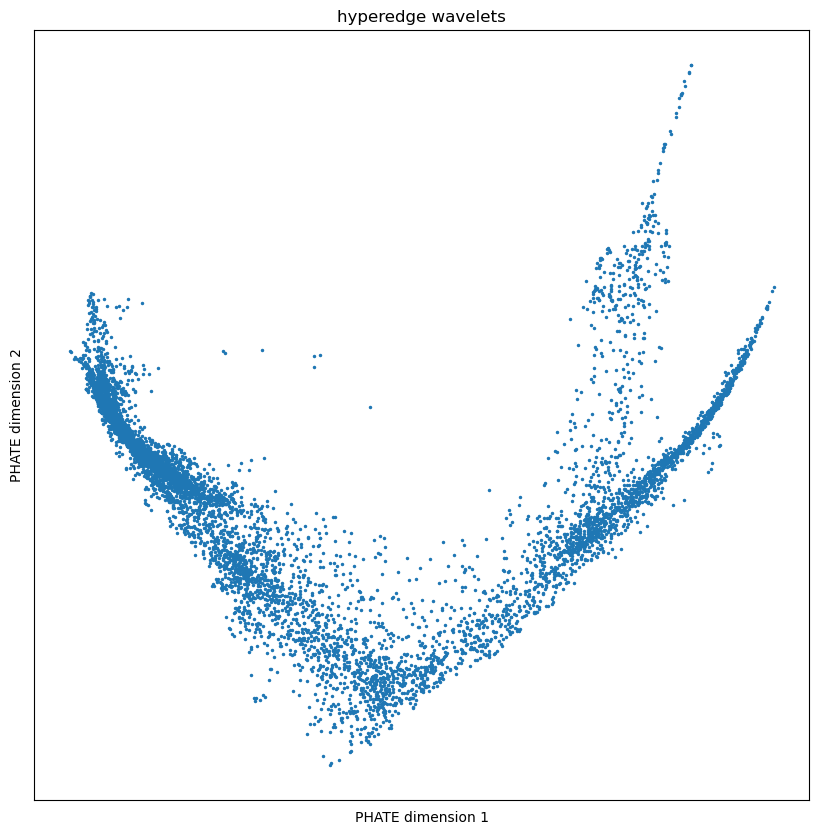

In [10]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)
scprep.plot.scatter2d(wv_phate, ax=ax, legend_loc='lower right')
ax.set_xlabel('PHATE dimension 1')
ax.set_ylabel('PHATE dimension 2')
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f'hyperedge wavelets')
plt.show()

In [11]:
np.random.seed(32)
dirac_sigs = np.random.choice([0, 1], size=X_data.shape, p=[1-0.002, 0.002])

In [12]:
init_node_sig = torch.from_numpy(dirac_sigs).to(device)
init_he_sig = torch.zeros(dataset[0].edge_attr.shape[0], X_data.shape[1], device=device)
heidx = dataset[0].edge_index.to(device)
s_nodes, s_edges = model(init_node_sig, heidx, hyperedge_attr = init_he_sig)

In [13]:
wvs = [s_edges[0,i,...].detach().cpu().numpy() for i in range(6)]
wvs_phate = []
phate_ops = []
for i in range(6):
    phate_op = phate.PHATE(verbose=0)
    wv0 = wvs[i]
    wv0_phate = phate_op.fit_transform(wv0)
    wvs_phate.append(wv0_phate)
    phate_ops.append(phate_op)

/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning: Detected zero distance between 18784 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:454: RuntimeWarning: overflow encountered in power
  K.data = np.exp(-1 * np.power(K.data, self.decay))


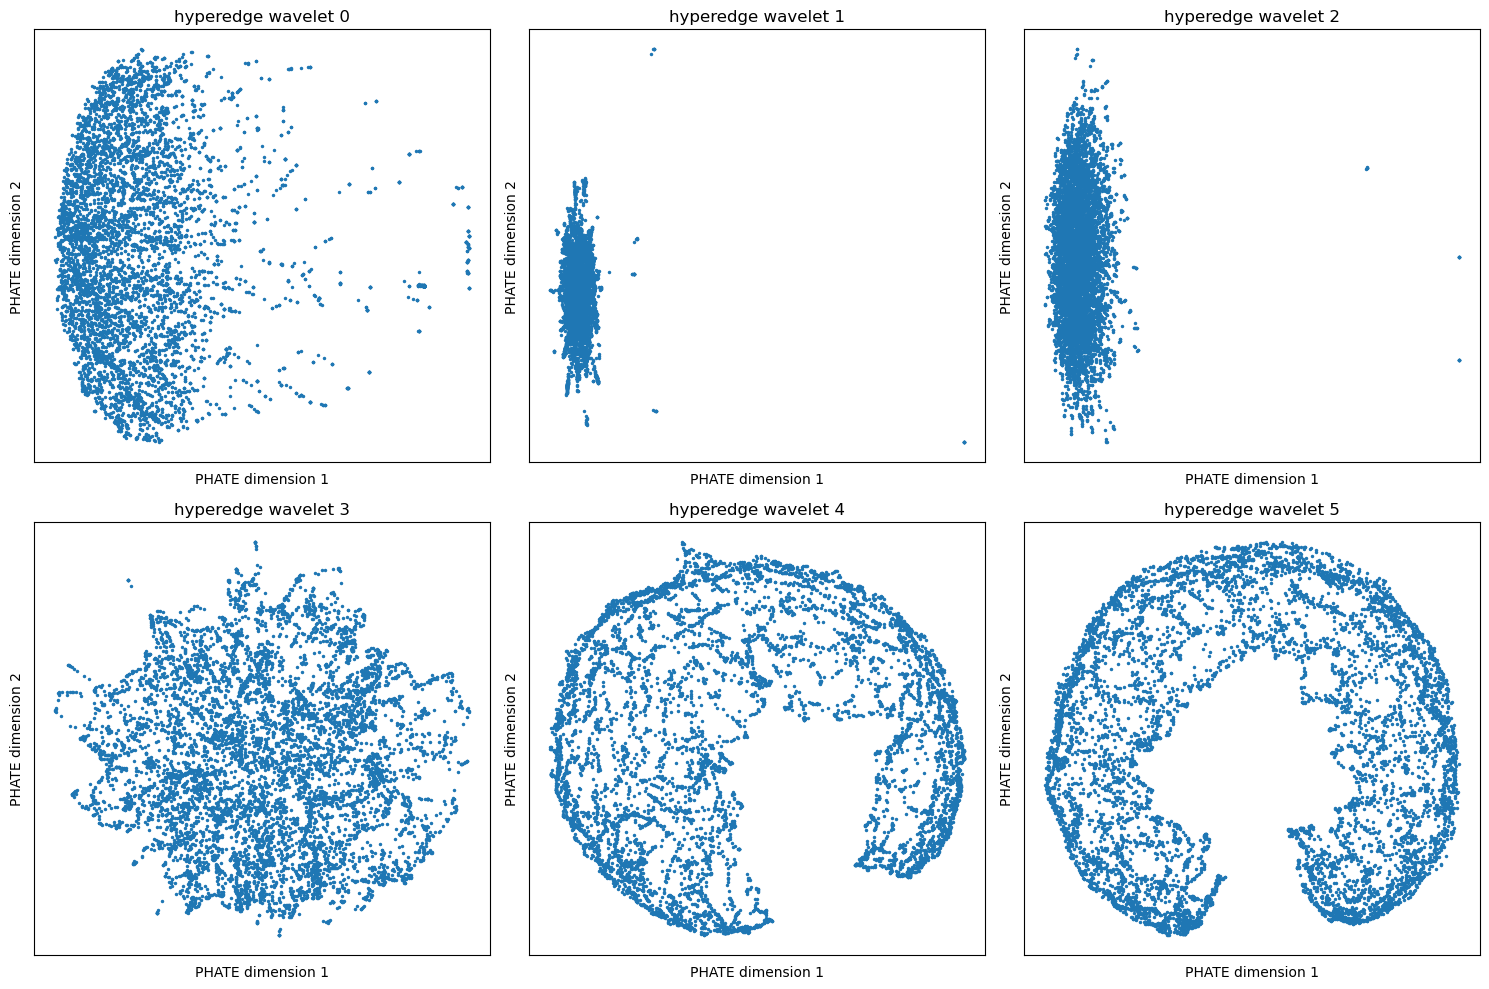

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    wv_phate = wvs_phate[i]
    scprep.plot.scatter2d(wv_phate, ax=ax, legend_loc='lower right')
    ax.set_xlabel('PHATE dimension 1')
    ax.set_ylabel('PHATE dimension 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'hyperedge wavelet {i}')

plt.tight_layout()
plt.show()

In [15]:
# wv_all = s_edges.view(8475, -1).detach().cpu().numpy()
wv_all = np.concatenate(wvs, axis=1)
phate_op = phate.PHATE(verbose=0)
wv_phate = phate_op.fit_transform(wv_all)

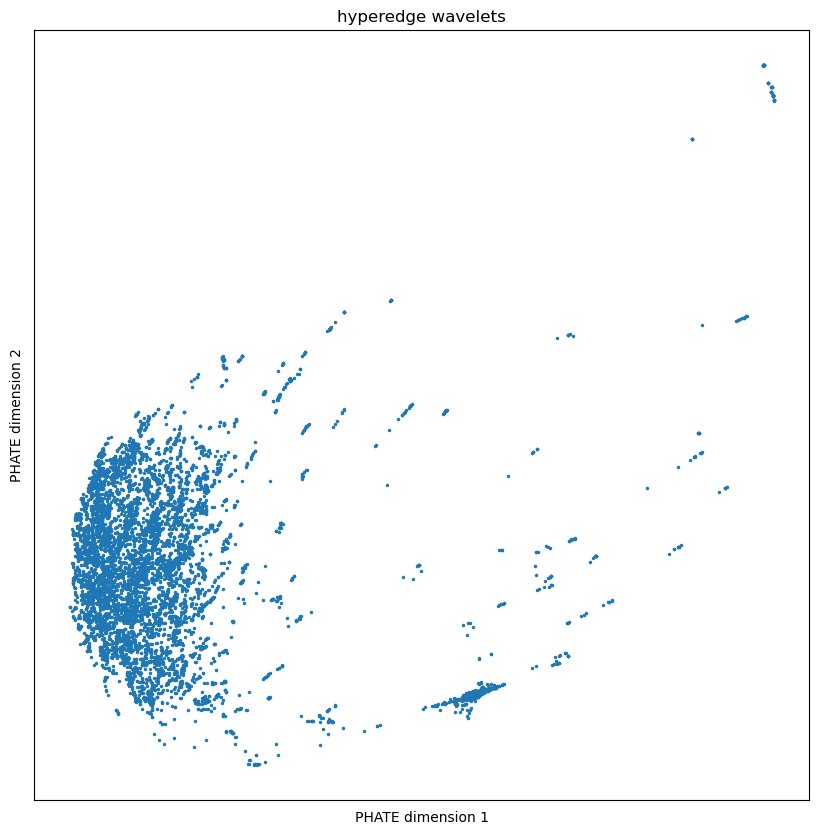

In [16]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)
scprep.plot.scatter2d(wv_phate, ax=ax, legend_loc='lower right')
ax.set_xlabel('PHATE dimension 1')
ax.set_ylabel('PHATE dimension 2')
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f'hyperedge wavelets')
plt.show()

In [17]:
init_node_sig = torch.from_numpy(dirac_sigs * X_data).to(device)
init_he_sig = torch.zeros(dataset[0].edge_attr.shape[0], X_data.shape[1], device=device)
heidx = dataset[0].edge_index.to(device)
s_nodes, s_edges = model(init_node_sig, heidx, hyperedge_attr = init_he_sig)

In [18]:
wvs = [s_edges[0,i,...].detach().cpu().numpy() for i in range(6)]
wvs_phate = []
phate_ops = []
for i in range(6):
    phate_op = phate.PHATE(verbose=0)
    wv0 = wvs[i]
    wv0_phate = phate_op.fit_transform(wv0)
    wvs_phate.append(wv0_phate)
    phate_ops.append(phate_op)

/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning: Detected zero distance between 88636 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:454: RuntimeWarning: overflow encountered in power
  K.data = np.exp(-1 * np.power(K.data, self.decay))
/home/xs272/.local/lib/python3.9/site-packages/graphtools/base.py:554: RuntimeWarning: K should have a non-zero diagonal
  warnings.warn("K should have a non-zero diagonal", RuntimeWarning)
/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning: Detected zero distance between 4170 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:454: RuntimeWarning: overflow encountered in power
  K.data = np.exp(-1 * np.power(K.data, self.decay))


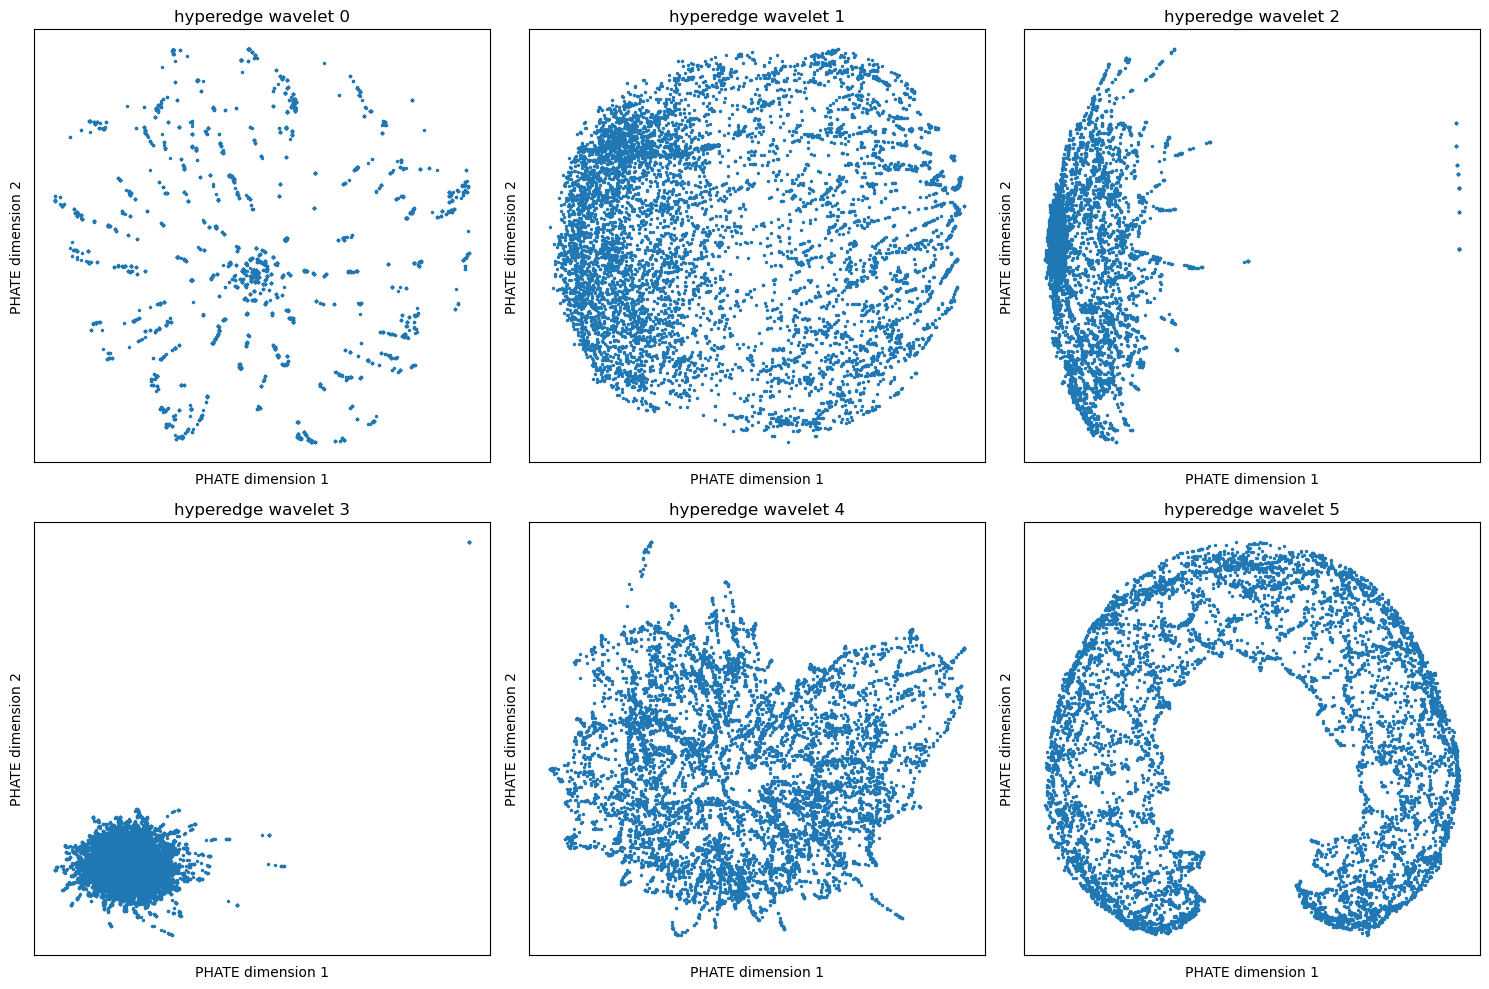

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    wv_phate = wvs_phate[i]
    scprep.plot.scatter2d(wv_phate, ax=ax, legend_loc='lower right')
    ax.set_xlabel('PHATE dimension 1')
    ax.set_ylabel('PHATE dimension 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'hyperedge wavelet {i}')

plt.tight_layout()
plt.show()

In [20]:
# wv_all = s_edges.view(8475, -1).detach().cpu().numpy()
wv_all = np.concatenate(wvs, axis=1)
phate_op = phate.PHATE(verbose=0)
wv_phate = phate_op.fit_transform(wv_all)

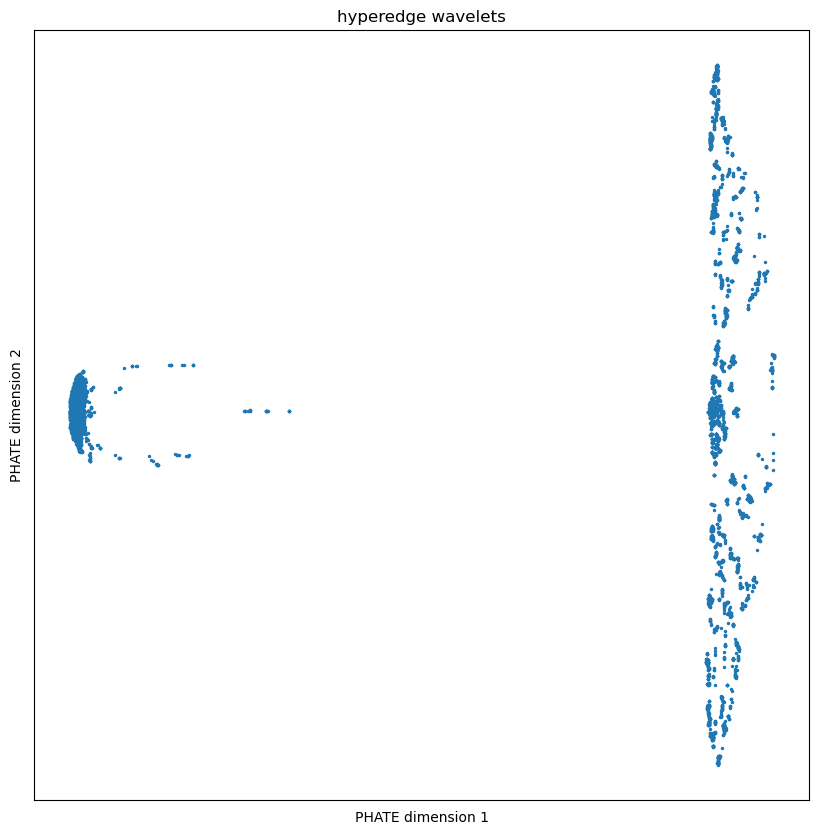

In [21]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)
scprep.plot.scatter2d(wv_phate, ax=ax, legend_loc='lower right')
ax.set_xlabel('PHATE dimension 1')
ax.set_ylabel('PHATE dimension 2')
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f'hyperedge wavelets')
plt.show()

In [22]:
np.random.seed(32)
dirac_sigs2 = np.random.choice([0, 1], size=X_data.shape, p=[1-0.01, 0.01])
init_node_sig = torch.from_numpy(dirac_sigs2 * X_data).to(device)
init_he_sig = torch.zeros(dataset[0].edge_attr.shape[0], X_data.shape[1], device=device)
heidx = dataset[0].edge_index.to(device)
s_nodes, s_edges = model(init_node_sig, heidx, hyperedge_attr = init_he_sig)

In [23]:
wvs = [s_edges[0,i,...].detach().cpu().numpy() for i in range(6)]
wvs_phate = []
phate_ops = []
for i in range(6):
    phate_op = phate.PHATE(verbose=0)
    wv0 = wvs[i]
    wv0_phate = phate_op.fit_transform(wv0)
    wvs_phate.append(wv0_phate)
    phate_ops.append(phate_op)

/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:290: RuntimeWarning: Detected zero distance between 11221 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
/home/xs272/.local/lib/python3.9/site-packages/graphtools/graphs.py:454: RuntimeWarning: overflow encountered in power
  K.data = np.exp(-1 * np.power(K.data, self.decay))


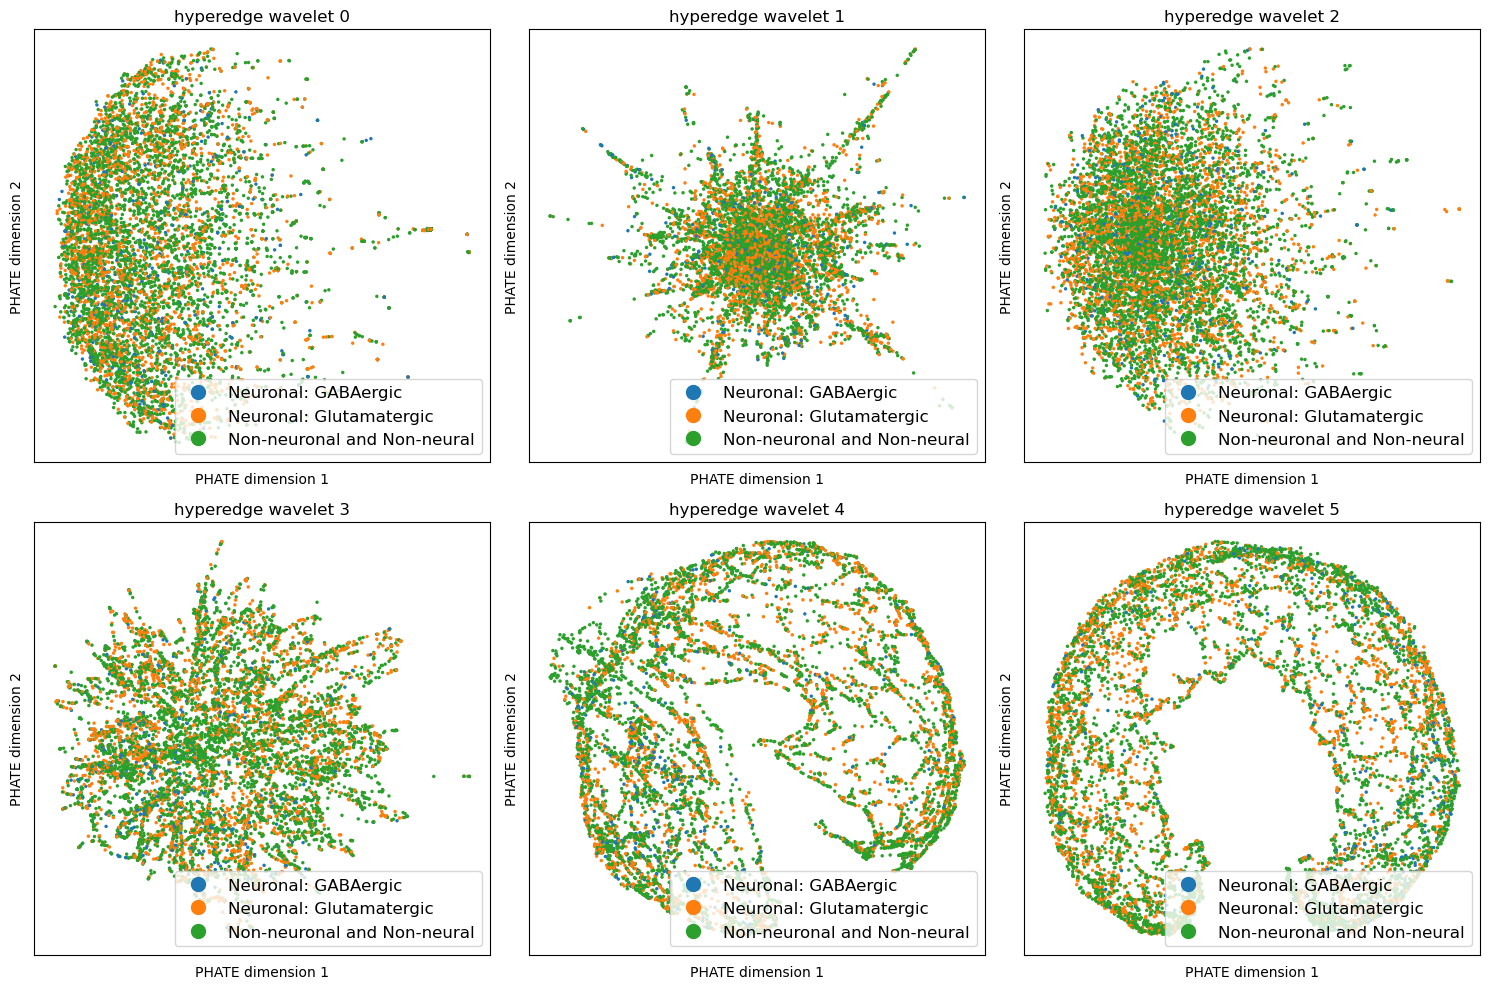

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    wv_phate = wvs_phate[i]
    scprep.plot.scatter2d(wv_phate, ax=ax, legend_loc='lower right')
    ax.set_xlabel('PHATE dimension 1')
    ax.set_ylabel('PHATE dimension 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'hyperedge wavelet {i}')

plt.tight_layout()
plt.show()

In [ ]:
# wv_all = s_edges.view(8475, -1).detach().cpu().numpy()
wv_all = np.concatenate(wvs, axis=1)
phate_op = phate.PHATE(verbose=0)
wv_phate = phate_op.fit_transform(wv_all)

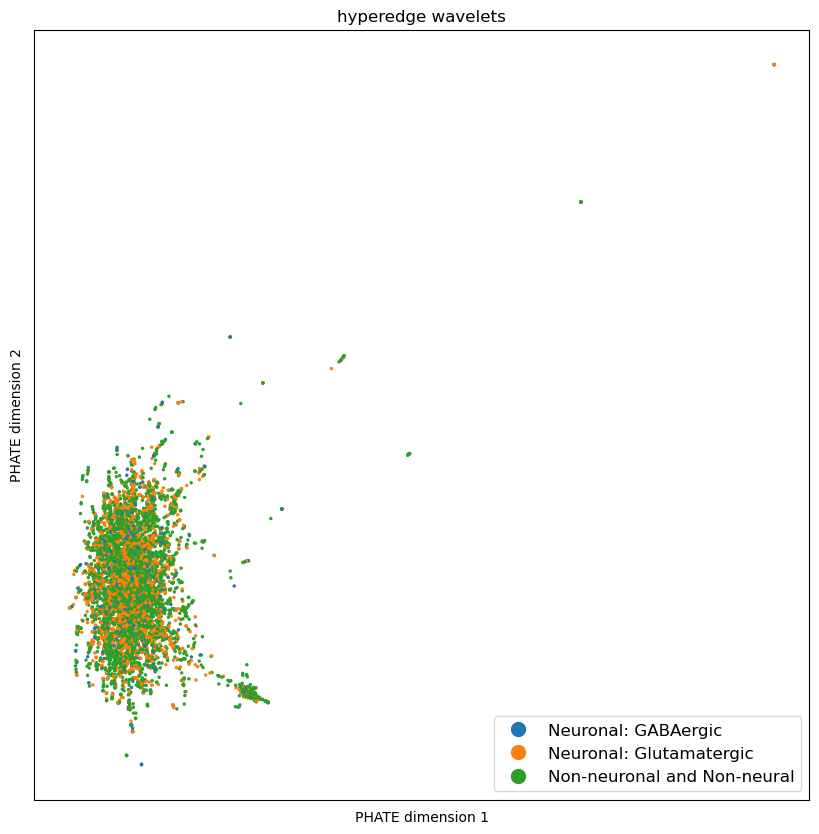

In [ ]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)
scprep.plot.scatter2d(wv_phate, ax=ax, legend_loc='lower right')
ax.set_xlabel('PHATE dimension 1')
ax.set_ylabel('PHATE dimension 2')
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f'hyperedge wavelets')
plt.show()